$$Source/SInk$$


In [109]:
import numpy as np
import matplotlib.pyplot as plt

In [110]:
x = np.linspace(-5,5,200)
y = np.linspace(-5,5,200)

X,Y = np.meshgrid(x,y)

In [111]:
def source(X,Y,coords, Q=1.0):
    X= X-coords[0]
    Y=Y-coords[1]
    r2 = np.maximum((X**2 + Y**2),1e-8)
    u = Q/(np.pi*2)*(X/r2)
    v = Q/(np.pi*2)*(Y/r2)

    return u,v

def uniform(u):
    return u

<function matplotlib.pyplot.show(close=None, block=None)>

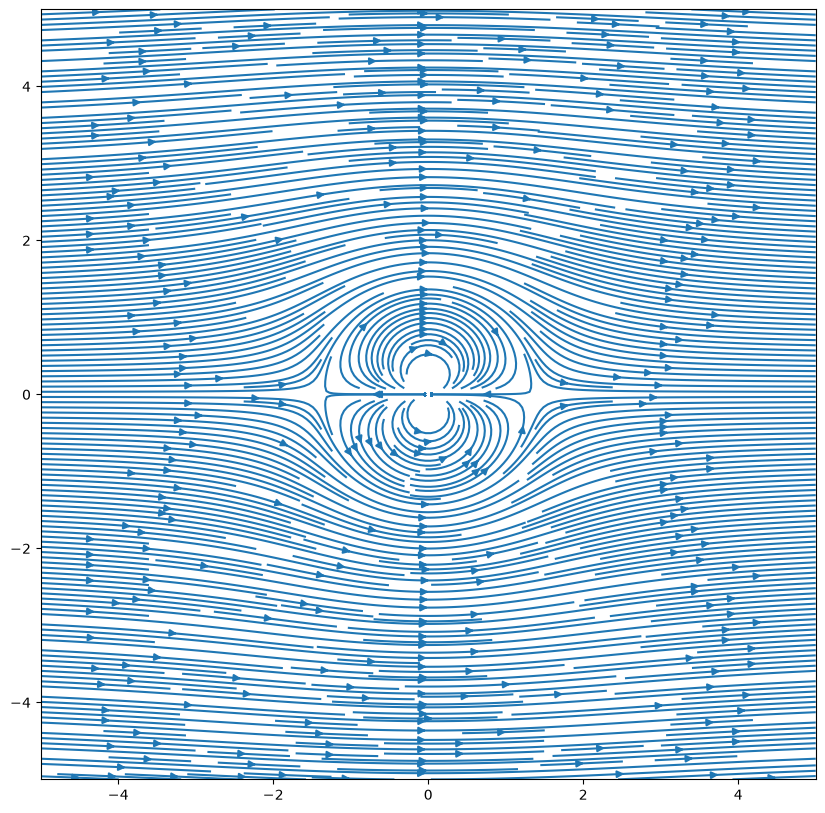

In [112]:
U1,V1 = source(X,Y,[-0.01,0],4)
U2,V2 = source(X,Y,[0.01,0],-4)
u = uniform(0.007)
U,V = U1+U2+u, V1+V2

plt.figure(figsize=(10,10))
plt.streamplot(X,Y,U,V, density = 5)
plt.show

AI for Prettier Visualization


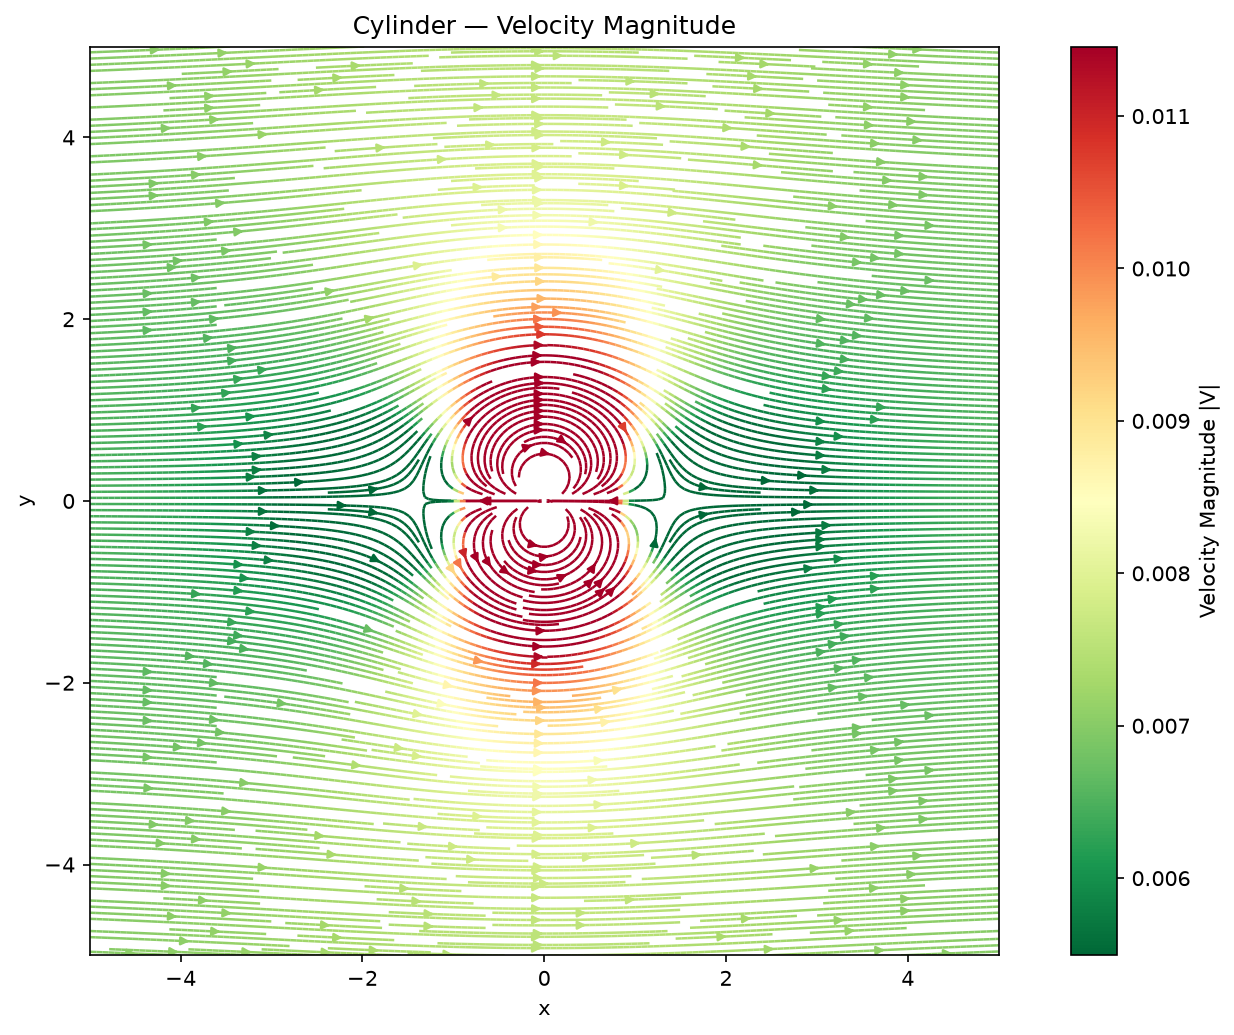

In [113]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import Normalize

# Calculate velocity magnitude (speed) at every grid point
speed = np.sqrt(U**2 + V**2)

# Clip the colour scale to reduce the influence of extreme velocities
vmin = np.percentile(speed, 5)
vmax = np.percentile(speed, 95)
norm = Normalize(vmin=vmin, vmax=vmax)

fig, ax = plt.subplots(figsize=(10, 7), dpi=150)

# Colour streamlines according to local speed
stream = ax.streamplot(
    X, Y, U, V,
    color=speed,
    cmap="RdYlGn_r",
    norm=norm,
    density=5,
    linewidth=1.2,
    arrowsize=0.8
)

# Add a colour bar
cbar = fig.colorbar(stream.lines, ax=ax)
cbar.set_label("Velocity Magnitude |V|")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Cylinder — Velocity Magnitude")
ax.set_aspect("equal")
ax.set_xlim(-5, 5)
ax.set_ylim(-5, 5)

plt.tight_layout()
plt.show()


Finding the Stream function and the Potential function from the velocities 

In [114]:
from scipy.integrate import cumulative_trapezoid


psi_numerical = np.zeros_like(U)

# along the bottom edge 
psi_numerical[0,:] = cumulative_trapezoid(-V[0,:], X[0,:], initial=0)

# along the y direction for every x column
for i in range(X.shape[1]):
    psi_numerical[:,i] = psi_numerical[0,i]+cumulative_trapezoid(U[:,i], Y[:,i], initial=0)

In [115]:
tolerance = 0.05 

mask = np.abs(U) < tolerance
X_zero = X[mask]
Y_zero = Y[mask]

print(f"u is zero at ({X_zero[:5]},{Y_zero[:5]})")

u is zero at ([-5.         -4.94974874 -4.89949749 -4.84924623 -4.79899497],[-5. -5. -5. -5. -5.])


$$\text{Adding circulation and calculating the lift of the cylinder}$$

In [116]:
def vortex(X,Y,coords, tau=0.05):

    X= X-coords[0]
    Y=Y-coords[1]
    r2 = np.maximum((X**2 + Y**2),1e-8)
    u = tau/(np.pi*2)*Y/(r2)
    v = -tau/(np.pi*2)*(X/r2)
    return u,v

U_vortex, V_vortex = vortex(X,Y,[0,0],0.05)

U = U + U_vortex
V = V+V_vortex




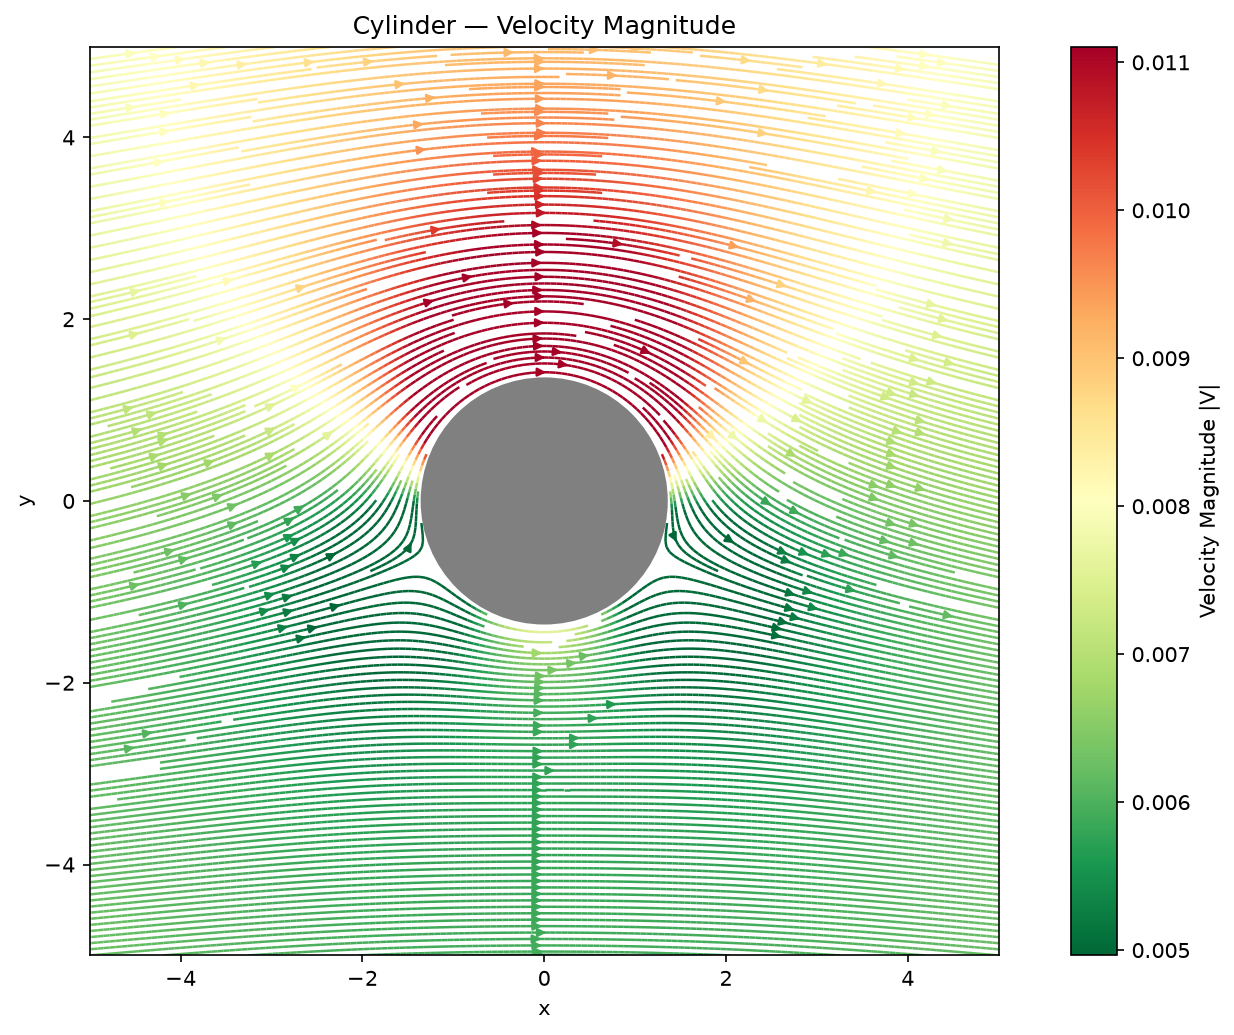

In [117]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# Define cylinder radius (assuming R = 1.0 for this example)
R = 1.348 

# Calculate velocity magnitude (speed) at every grid point
speed = np.sqrt(U**2 + V**2)

# --- NEW: Mask the inside of the cylinder ---
inside_cylinder = (X**2 + Y**2) < R**2
U[inside_cylinder] = np.nan
V[inside_cylinder] = np.nan
speed[inside_cylinder] = np.nan
# --------------------------------------------

# Clip the colour scale to reduce the influence of extreme velocities
vmin = np.nanpercentile(speed, 5)   # Use nanpercentile to ignore the NaNs we just added
vmax = np.nanpercentile(speed, 95)
norm = Normalize(vmin=vmin, vmax=vmax)

fig, ax = plt.subplots(figsize=(10, 7), dpi=150)

# Colour streamlines according to local speed
stream = ax.streamplot(
    X, Y, U, V,
    color=speed,
    cmap="RdYlGn_r",
    norm=norm,
    density=5,
    linewidth=1.2,
    arrowsize=0.8
)

# --- NEW: Draw the solid cylinder ---
cylinder = plt.Circle((0, 0), R, color='gray', zorder=5)
ax.add_patch(cylinder)
# ------------------------------------

# Add a colour bar
cbar = fig.colorbar(stream.lines, ax=ax)
cbar.set_label("Velocity Magnitude |V|")

ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Cylinder — Velocity Magnitude")
ax.set_aspect("equal")
ax.set_xlim(-5, 5)
ax.set_ylim(-5, 5)

plt.tight_layout()
plt.show()

In [118]:
def pressure(X,Y, speed,rho=1.24):
    

    p= 1/2*rho*(u**2-speed**2)
    return p

pressure_field= pressure(X,Y,speed)

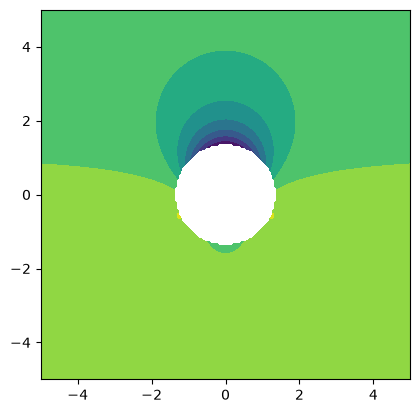

In [119]:
plt.contourf(X, Y, pressure_field)

plt.gca().set_aspect('equal')
# this line fixes strectching 
plt.show()

In [120]:
surface = (X**2 + Y**2)==R

X_surface , Y_surface = X[surface] , Y[surface]
pressure_surface = pressure(X_surface,Y_surface,speed)


##Wrong 


In [121]:
#CORRECT!!!
import scipy as sp
theta = np.linspace(0, 2*np.pi, 200)
X_surface = R * np.cos(theta)
Y_surface = R * np.sin(theta)

pressure_surface = pressure(X_surface,Y_surface,speed)

integrand = -pressure_surface*np.sin(theta)*R

lift = sp.integrate.trapezoid(integrand, theta)


In [124]:
import scipy as sp

# 1. Define the 1D path
theta = np.linspace(0, 2*np.pi, 200)
X_surface = R * np.cos(theta)
Y_surface = R * np.sin(theta)

# 2. Calculate the exact 1D velocity ON the surface using your functions
u_surf = uniform(u) + source(X_surface, Y_surface, [-0.01, 0], 4)[0] + source(X_surface, Y_surface, [0.01, 0], -4)[0] + vortex(X_surface, Y_surface, [0, 0])[0]
v_surf = source(X_surface, Y_surface, [-0.01, 0], 4)[1] + source(X_surface, Y_surface, [0.01, 0], -4)[1] + vortex(X_surface, Y_surface, [0, 0])[1]

speed_surface = np.sqrt(u_surf**2 + v_surf**2)

# 3. Calculate 1D pressure explicitly
pressure_surface =  0.5 * 1.24*(2- speed_surface**2)

# 4. Integrate
integrand = -pressure_surface * np.sin(theta) * R
lift = sp.integrate.trapezoid(integrand, theta)

print(lift) # This will now be a single scalar number!
lift_kj = 1.24 * u * 0.05
lift_kj

0.0004342161080859164


0.00043400000000000003

$$\text{Why 1 D velocities?}$$

The sp.integrate.trapezoid function is designed to return a single scalar value (your total lift) when you integrate a 1D array over your 1D theta path.   The fact that it returned a large array means your integrand was accidentally a 2D matrix. This happened because you passed speed into your pressure() function. In your previous code, speed was defined as a 200x200 meshgrid representing the entire spatial domain. When you mix the 1D X_surface and 2D speed arrays, Python broadcasts them into a larger 2D array. The integration function then integrated across only one axis of that matrix, returning an array of answers instead of one total sum